# Лабораторная работа №1

Тема: низкоуровневый анализ, предобработка текста и статистическое языковое моделирование.

Датасет: AG News, новости из 4 категорий (World, Sports, Business, Sci/Tech). Загружаю его через библиотеку `datasets` (HuggingFace), это тот же датасет, что и на Kaggle.

## 1. Загрузка данных и разбиение на Train/Test

Целевая текстовая колонка: `text` (в ней уже склеены заголовок и описание новости). Целевой класс: `label`.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

In [2]:
# если библиотеки нет: !pip install datasets
from datasets import load_dataset

raw = load_dataset('fancyzhx/ag_news')

df = pd.DataFrame(raw['train'])
df['label'] = df['label'] + 1  # в HuggingFace метки 0-3, сдвигаю на 1-4

print(f'Размер датасета: {df.shape}')
print(f'Распределение классов:\n{df["label"].value_counts().sort_index()}')
df.head(3)

Размер датасета: (120000, 2)
Распределение классов:
label
1    30000
2    30000
3    30000
4    30000
Name: count, dtype: int64


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,3
1,Carlyle Looks Toward Commercial Aerospace (Reu...,3
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,3


In [3]:
LABEL_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
df['category'] = df['label'].map(LABEL_MAP)

print(df['text'].iloc[0])

Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


In [4]:
train_df, test_df = train_test_split(
    df[['text', 'label', 'category']],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df['label'],
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'Train: {len(train_df)}, Test: {len(test_df)}')
print(train_df['category'].value_counts().sort_index())
print(test_df['category'].value_counts().sort_index())

Train: 96000, Test: 24000
category
Business    24000
Sci/Tech    24000
Sports      24000
World       24000
Name: count, dtype: int64
category
Business    6000
Sci/Tech    6000
Sports      6000
World       6000
Name: count, dtype: int64


Классы в исходных данных сбалансированы, стратификация сохранила одинаковые доли классов в Train и Test.

## 2. Анализ структуры данных (только Train)

Все подсчёты в этом разделе делаю только на обучающей выборке.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
STOP_WORDS = set(stopwords.words('english'))

sns.set_theme(style='whitegrid')

### 2.1 Размер выборки и длина текстов

In [6]:
train_df['n_chars'] = train_df['text'].str.len()
train_df['n_words'] = train_df['text'].str.split().str.len()

print(f'Документов в Train: {len(train_df):,}')
print(f'Средняя длина в словах: {train_df["n_words"].mean():.1f}')
print(f'Средняя длина в символах: {train_df["n_chars"].mean():.1f}')

Документов в Train: 96,000
Средняя длина в словах: 37.9
Средняя длина в символах: 236.6


### 2.2 Распределение длин текстов

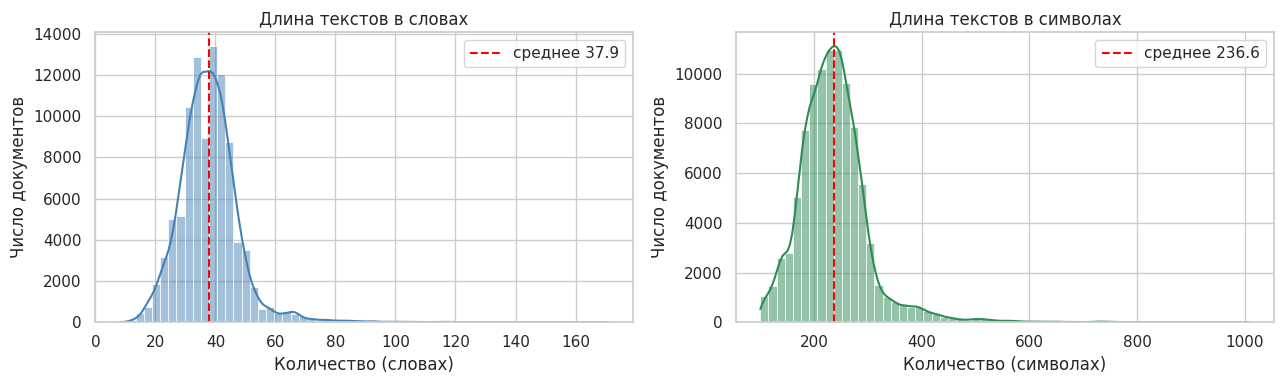

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col, name, color in [
    (axes[0], 'n_words', 'словах', 'steelblue'),
    (axes[1], 'n_chars', 'символах', 'seagreen'),
]:
    sns.histplot(train_df[col], bins=60, kde=True, ax=ax, color=color)
    ax.axvline(train_df[col].mean(), color='red', linestyle='--',
               label=f'среднее {train_df[col].mean():.1f}')
    ax.set_title(f'Длина текстов в {name}')
    ax.set_xlabel(f'Количество ({name})')
    ax.set_ylabel('Число документов')
    ax.legend()

plt.tight_layout()
plt.show()

### 2.3 Топ-30 стоп-слов

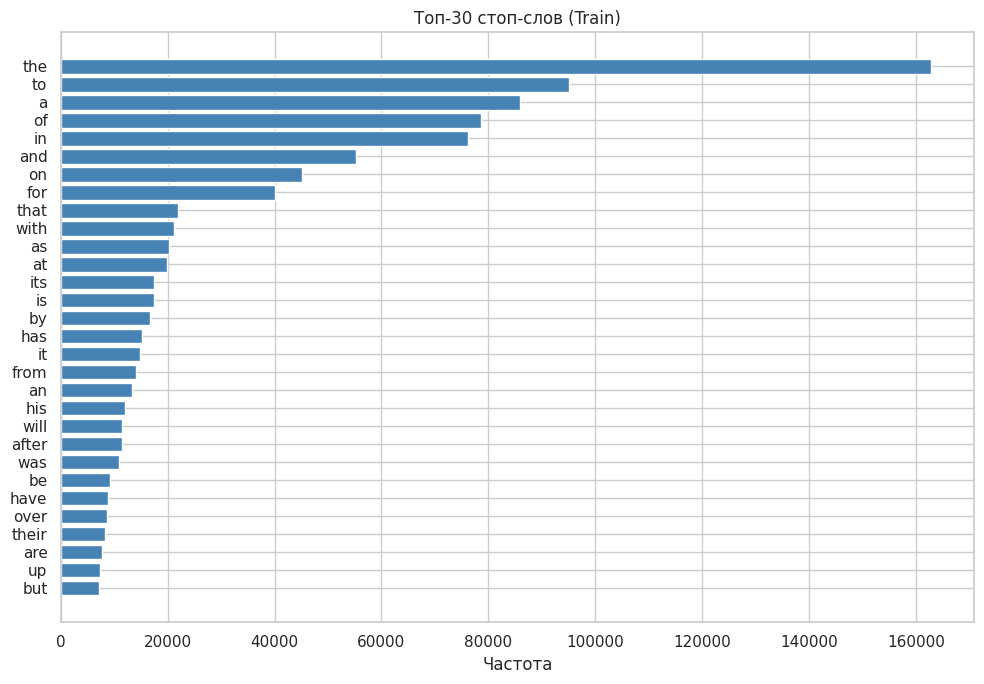

Всего токенов в Train: 3,635,437
Из них стоп-слова: 1,108,773 (30.5%)


In [8]:
# токенизация по пробелам, для частотного анализа этого достаточно
words = train_df['text'].str.lower().str.split().explode()

stop_counts = Counter(words[words.isin(STOP_WORDS)])
labels, freqs = zip(*stop_counts.most_common(30))

plt.figure(figsize=(10, 7))
plt.barh(labels, freqs, color='steelblue')
plt.gca().invert_yaxis()
plt.title('Топ-30 стоп-слов (Train)')
plt.xlabel('Частота')
plt.tight_layout()
plt.show()

print(f'Всего токенов в Train: {len(words):,}')
print(f'Из них стоп-слова: {stop_counts.total():,} ({stop_counts.total() / len(words) * 100:.1f}%)')

## 3. Поиск шума в тексте

Датасет собран автоматически из новостных лент, поэтому проверяю типичные для веб-текстов виды шума: HTML-разметку, ссылки и адреса почты, обрывы и многоточия, нестандартные символы. Для каждого типа считаю, в скольких документах Train он встречается, и показываю примеры. Если шума нет, это видно по нулям.

In [9]:
import re
from IPython.display import display

def noise_audit(series, pattern, label, n_examples=3):
    """Ищет паттерн в текстах, печатает статистику и примеры."""
    regex = re.compile(pattern, re.IGNORECASE)
    has_noise = series.str.contains(regex, na=False)
    matches = [m for text in series for m in regex.findall(text)]
    n_docs = has_noise.sum()

    print(f'[{label}]')
    print(f'  документов с шумом: {n_docs:,} ({n_docs / len(series) * 100:.2f}%)')
    print(f'  всего вхождений: {len(matches):,}')
    if matches:
        print(f'  примеры совпадений: {list(dict.fromkeys(matches))[:5]}')
        for text in series[has_noise].head(n_examples):
            hit = regex.search(text)
            start = max(0, hit.start() - 40)
            end = min(len(text), hit.end() + 40)
            print(f'  контекст: ...{text[start:end]}...')
    print()

### Тип 1. HTML-теги и HTML-сущности

In [10]:
noise_audit(train_df['text'], r'<[^>]+>', 'HTML-теги')
noise_audit(train_df['text'], r'&(?:[a-z]+|#\d+);', 'HTML-сущности')
noise_audit(train_df['text'], r'(?<![&\w])(?:#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);',
            'HTML-сущности без амперсанда')

[HTML-теги]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0

[HTML-сущности]
  документов с шумом: 4,192 (4.37%)
  всего вхождений: 21,070
  примеры совпадений: ['&lt;', '&gt;']


  контекст: ..., take note - chilly environs may lower &lt;b&gt;...&lt;/b&gt; If your office is oft...
  контекст: ...es axe as Microsoft dismembers Longhorn &lt;strong&gt;Exclusive&lt;/strong&gt; WinFS...
  контекст: ...eting Internet service providers (ISPs).&lt;p&gt;ADVERTISEMENT&lt;/p&gt;&lt;p&gt;&lt...



[HTML-сущности без амперсанда]
  документов с шумом: 27,662 (28.81%)
  всего вхождений: 46,448
  примеры совпадений: ['#151;', '#39;', 'quot;', 'amp;', '#36;']
  контекст: ...ierra (AP) AP - A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a rem...
  контекст: ...Virgin #39;s next destination: space LONDON Richard...
  контекст: ... Coast shoppers get their holiday money #39;s worth on the biggest shopping day of t...



### Тип 2. URL-адреса и e-mail

In [11]:
noise_audit(train_df['text'], r'https?://\S+|www\.\S+', 'URL-адреса')
noise_audit(train_df['text'],
            r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b',
            'E-mail адреса')

[URL-адреса]
  документов с шумом: 1,483 (1.54%)
  всего вхождений: 1,820
  примеры совпадений: ['http://ad.doubleclick.net/ad/idg.us.ifw.general/solaris;sz=1x1;ord=200301151450?"', 'http://ad.doubleclick.net/clk;12204780;10550054;n?http://ad.doubleclick.net/clk;12165994;10522295;g?http://www.sun.com/solaris10"&gt;Solaris', 'http://www.investor.reuters.com/FullQuote.aspx?ticker=NYT.N', 'http://www.investor.reuters.com/FullQuote.aspx?ticker=EAUG.PA', 'http://www.investor.reuters.com/FullQuote.aspx?ticker=CA.N']
  контекст: ...TISEMENT&lt;/p&gt;&lt;p&gt;&lt;img src="http://ad.doubleclick.net/ad/idg.us.ifw.general/solaris;sz=1x1;ord=200301151450?" width="1" height="1" border="0"/&gt;&lt...
  контекст: ...s) - The New York Times Co. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=NYT.N target=/stocks/quickinfo/fullquote"&gt;...
  контекст: ...rs fined Vivendi Universal  &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=EAUG.PA target=/stocks/quickinfo/full

[E-mail адреса]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0



### Тип 3. Признаки обрезанного текста: точка с запятой в конце, многоточие, незакрытая скобка

In [12]:
noise_audit(train_df['text'], r'\s;\s*$', 'Точка с запятой в конце строки')
noise_audit(train_df['text'], r'\.{3,}', 'Многоточие')
noise_audit(train_df['text'], r'\([^)]*$', 'Незакрытая скобка в конце')

[Точка с запятой в конце строки]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0



[Многоточие]
  документов с шумом: 5,707 (5.94%)
  всего вхождений: 6,008
  примеры совпадений: ['...', '....', '.....', '......']
  контекст: ...o craigslist officials.\\With dedicated ......
  контекст: ...tered with developing a next-generation ......
  контекст: ...te - chilly environs may lower &lt;b&gt;...&lt;/b&gt; If your office is often cold,...

[Незакрытая скобка в конце]
  документов с шумом: 270 (0.28%)
  всего вхождений: 270
  примеры совпадений: ['(\\$178.', '(\\$1.', '(2.', '(Australian time because of a leg injury.', '(312bn ']
  контекст: ...vice provider Softbank for 72.4 million (\$178....
  контекст: ... 3-6 6-3 7-6 to Thomas Johansson in the (\$1....
  контекст: ...f a restructuring designed to cut \$5bn (2....



### Тип 4. Не-ASCII символы

In [13]:
noise_audit(train_df['text'], r'[^\x00-\x7F]', 'Не-ASCII символы')
noise_audit(train_df['text'], r'\xa0|\u00a0', 'Неразрывный пробел')
noise_audit(train_df['text'], r'[\u2018\u2019\u201c\u201d\u2013\u2014]',
            'Типографские кавычки и тире')

[Не-ASCII символы]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0

[Неразрывный пробел]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0



[Типографские кавычки и тире]
  документов с шумом: 0 (0.00%)
  всего вхождений: 0



### Итоги

| Тип шума | Документов | % от Train | Всего вхождений |
|---|---:|---:|---:|
| HTML-теги | 0 | 0.00% | 0 |
| HTML-сущности (`&lt;`, `&gt;`) | 4 192 | 4.37% | 21 070 |
| HTML-сущности без амперсанда (`#39;`, `quot;`) | 27 662 | 28.81% | 46 448 |
| URL-адреса | 1 483 | 1.54% | 1 820 |
| E-mail | 0 | 0.00% | 0 |
| Точка с запятой в конце | 0 | 0.00% | 0 |
| Многоточие | 5 707 | 5.94% | 6 008 |
| Незакрытая скобка | 270 | 0.28% | 270 |
| Не-ASCII символы | 0 | 0.00% | 0 |
| Неразрывный пробел | 0 | 0.00% | 0 |
| Типографские кавычки и тире | 0 | 0.00% | 0 |

Требуют очистки: сущности без амперсанда (самый частый шум: `#39;` это апостроф, `quot;` кавычка, `#151;` тире), HTML-сущности, URL-адреса, многоточия, а также незакрытые скобки (их мало).
Не найдены: HTML-теги, e-mail, точка с запятой в конце, не-ASCII символы, неразрывные пробелы, типографские кавычки и тире.

HTML-теги в виде `<b>` не нашлись, но в тексте есть сущности `&lt;` и `&gt;`. Это те же теги, закодированные дважды (`&lt;b&gt;`), поэтому при очистке сначала нужно декодировать сущности и только потом удалять теги.

## 4. Конвейер очистки текста

Правила применяются по порядку, для каждого типа шума своё правило:

1. Сущности без амперсанда (`#39;`, `quot;`, `amp;`) приводятся к обычному виду (`&#39;` и т.д.), после чего все HTML-сущности декодируются. Декодировать нужно до удаления тегов, потому что в данных теги записаны сущностями (`&lt;b&gt;`).
2. HTML-теги удаляются.
3. URL заменяются на `[URL]`, e-mail на `[EMAIL]`.
4. Точка с запятой в конце удаляется, многоточие заменяется одной точкой.
5. Типографские кавычки, апостроф и тире заменяются на ASCII-аналоги, остальные не-ASCII символы убираются.
6. Отдельно стоящие числа заменяются на `[NUM]`. Слова с цифрами (`F-16`, `COVID-19`, `magnitude-5.5`) не трогаются.
7. Обратные слэши и одиночные `#` убираются.
8. Текст разбивается на токены: знаки препинания, кавычки и скобки отделяются от слов пробелами, а `[NUM]`, `[URL]` и `[EMAIL]` остаются целыми токенами. Слова с дефисом или точкой внутри (`F-16`, `magnitude-5.5`, `u.s`) не разбиваются.
9. В начало и конец текста добавляются `<s>` и `</s>`.

In [14]:
import html
import unicodedata

RE_HTML_TAG = re.compile(r'<[^>]+>')
RE_ENTITY_NO_AMP = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')  # "#39;" без &
RE_URL = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
RE_EMAIL = re.compile(r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b')
RE_TRAIL_SEMI = re.compile(r'\s*;\s*$')
RE_ELLIPSIS = re.compile(r'\.{2,}')
RE_LQUOTE = re.compile(r'[\u2018\u201c\u00ab]')
RE_RQUOTE = re.compile(r'[\u201d\u00bb]')
RE_APOSTROPHE = re.compile(r'\u2019')
RE_DASH = re.compile(r'[\u2013\u2014\u2015]')
# число, перед которым нет буквы, дефиса, точки или запятой, и после которого нет буквы или дефиса
RE_NUMBER = re.compile(r'(?<![A-Za-z\-.,])\b\d+([.,]\d+)*\b(?![A-Za-z\-])')
RE_BACKSLASH = re.compile(r'\\+')
RE_LONE_HASH = re.compile(r'#(?=[^a-zA-Z]|$)')
# токен: служебный токен целиком, слово (с дефисом или точкой внутри) или один знак препинания
RE_TOKEN = re.compile(r'\[(?:NUM|URL|EMAIL)\]|\w+(?:[-.]\w+)*|[^\w\s]')

In [15]:
def clean_text(text):
    if not isinstance(text, str):
        return '<s> </s>'

    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub('[URL]', text)
    text = RE_EMAIL.sub('[EMAIL]', text)
    text = RE_TRAIL_SEMI.sub('', text)
    text = RE_ELLIPSIS.sub('.', text)

    text = RE_LQUOTE.sub('"', text)
    text = RE_RQUOTE.sub('"', text)
    text = RE_APOSTROPHE.sub("'", text)
    text = RE_DASH.sub('-', text)
    # остальные не-ASCII символы: раскладываем (é в e и знак) и выбрасываем всё не-ASCII
    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', errors='ignore').decode('ascii')

    text = RE_NUMBER.sub('[NUM]', text)
    text = RE_BACKSLASH.sub(' ', text)
    text = RE_LONE_HASH.sub(' ', text)

    tokens = RE_TOKEN.findall(text)
    return ' '.join(['<s>'] + tokens + ['</s>'])

### Проверка на тестовых примерах

In [16]:
test_cases = [
    "<p>Apple &amp; Google report $1.5 billion revenue in Q3 2024.</p>",
    "Visit https://www.reuters.com for more. The deal is worth 340 million.",
    "Contact us at editor@nytimes.com for details ;",
    "The CEO said \u201cwe are confident\u201d \u2014 and results prove it...",
    "NASA\u2019s F-16 flew 3 missions; COVID-19 cases rose by 200 in 2023.",
    "A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remote area.",
    "Wall Street #39;s dwindling band said  quot;no comment quot; to AT&amp;T.",
]

for raw_text in test_cases:
    print('IN :', raw_text)
    print('OUT:', clean_text(raw_text))
    print()

IN : <p>Apple &amp; Google report $1.5 billion revenue in Q3 2024.</p>
OUT: <s> Apple & Google report $ [NUM] billion revenue in Q3 [NUM] . </s>

IN : Visit https://www.reuters.com for more. The deal is worth 340 million.
OUT: <s> Visit [URL] for more . The deal is worth [NUM] million . </s>

IN : Contact us at editor@nytimes.com for details ;
OUT: <s> Contact us at [EMAIL] for details </s>

IN : The CEO said “we are confident” — and results prove it...
OUT: <s> The CEO said " we are confident " - and results prove it . </s>

IN : NASA’s F-16 flew 3 missions; COVID-19 cases rose by 200 in 2023.
OUT: <s> NASA ' s F-16 flew [NUM] missions ; COVID-19 cases rose by [NUM] in [NUM] . </s>

IN : A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remote area.
OUT: <s> A swarm of earthquakes - one a magnitude-5.5 - jolted a remote area . </s>

IN : Wall Street #39;s dwindling band said  quot;no comment quot; to AT&amp;T.
OUT: <s> Wall Street ' s dwindling band said " no comment "

### Применение к Train и Test

In [17]:
train_df['text_clean'] = train_df['text'].apply(clean_text)
test_df['text_clean'] = test_df['text'].apply(clean_text)

for i in range(3):
    print(f'[{i}] до   : {train_df["text"][i][:120]}')
    print(f'[{i}] после: {train_df["text_clean"][i][:120]}')
    print()

[0] до   : Clijsters Unsure About Latest Injury, Says Hewitt  TOKYO (Reuters) - Belgian Kim Clijsters is unsure about the  exact na
[0] после: <s> Clijsters Unsure About Latest Injury , Says Hewitt TOKYO ( Reuters ) - Belgian Kim Clijsters is unsure about the exa

[1] до   : Earthquake Swarm Shakes Eastern Sierra (AP) AP - A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remot
[1] после: <s> Earthquake Swarm Shakes Eastern Sierra ( AP ) AP - A swarm of earthquakes - one a magnitude-5.5 - jolted a remote , 

[2] до   : Issues related to war in Iraq help define election in Australia SYDNEY -- On one side is the incumbent, a conservative c
[2] после: <s> Issues related to war in Iraq help define election in Australia SYDNEY - - On one side is the incumbent , a conserva



## 5. Нормализация: стемминг и лемматизация

Нормализация приводит разные формы слова к одной, за счёт этого словарь уменьшается. Сравниваю два стеммера (Porter и Snowball) и лемматизацию spaCy по размеру словаря. Нормализую только уникальные токены и строю словарь соответствий "слово: основа", это быстрее, чем обрабатывать каждое вхождение.

In [18]:
import time
import spacy
from nltk.stem import PorterStemmer, SnowballStemmer

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

porter = PorterStemmer()
snowball = SnowballStemmer('english')

### 5.1 Словарь до нормализации

In [19]:
SERVICE_TOKENS = {'<s>', '</s>', '[NUM]', '[URL]', '[EMAIL]'}

def extract_tokens(series):
    """Все токены очищенных текстов без <s> и </s>, слова в нижнем регистре."""
    tokens = series.str.split().explode().dropna()
    return [t if t in SERVICE_TOKENS else t.lower()
            for t in tokens if t not in ('<s>', '</s>')]

all_tokens = extract_tokens(train_df['text_clean'])
unique_tokens = sorted(set(all_tokens))

print(f'Всего токенов (N): {len(all_tokens):,}')
print(f'Уникальных токенов (|V|): {len(unique_tokens):,}')
print(f'Type-Token Ratio: {len(unique_tokens) / len(all_tokens):.4f}')

Всего токенов (N): 4,102,755
Уникальных токенов (|V|): 74,455
Type-Token Ratio: 0.0181


### 5.2 Стемминг

In [20]:
t0 = time.perf_counter()
porter_map = {tok: tok if tok in SERVICE_TOKENS else porter.stem(tok) for tok in unique_tokens}
t_porter = time.perf_counter() - t0

t0 = time.perf_counter()
snowball_map = {tok: tok if tok in SERVICE_TOKENS else snowball.stem(tok) for tok in unique_tokens}
t_snowball = time.perf_counter() - t0

vocab_porter = set(porter_map.values())
vocab_snowball = set(snowball_map.values())

print(f'Porter:   |V| = {len(vocab_porter):,}, сжатие {(1 - len(vocab_porter) / len(unique_tokens)) * 100:.1f}%, {t_porter:.2f} с')
print(f'Snowball: |V| = {len(vocab_snowball):,}, сжатие {(1 - len(vocab_snowball) / len(unique_tokens)) * 100:.1f}%, {t_snowball:.2f} с')

Porter:   |V| = 56,638, сжатие 23.9%, 0.88 с
Snowball: |V| = 56,548, сжатие 24.1%, 0.71 с


### 5.3 Лемматизация

In [21]:
t0 = time.perf_counter()
lemma_map = {tok: tok for tok in SERVICE_TOKENS}
words_to_lemmatize = [tok for tok in unique_tokens if tok not in SERVICE_TOKENS]
for doc in nlp.pipe(words_to_lemmatize, batch_size=2048):
    # если spaCy разбил токен на несколько частей, оставляем токен как есть
    lemma_map[doc.text] = doc[0].lemma_.lower() if len(doc) == 1 else doc.text
t_lemma = time.perf_counter() - t0

vocab_lemma = set(lemma_map.values())

print(f'spaCy: |V| = {len(vocab_lemma):,}, сжатие {(1 - len(vocab_lemma) / len(unique_tokens)) * 100:.1f}%, {t_lemma:.2f} с')

spaCy: |V| = 61,435, сжатие 17.5%, 24.55 с


### 5.4 Примеры на словах из корпуса

Беру частые слова (только буквы, длиной от 4 символов, не меньше 50 вхождений), у которых Porter даёт одинаковую основу. Это как раз случаи, где разные слова склеиваются в одно.

In [22]:
from collections import defaultdict

word_freq = Counter(all_tokens)

candidate_words = [
    w for w, cnt in word_freq.items()
    if w.isalpha() and len(w) >= 4 and cnt >= 50
]

stem_groups = defaultdict(list)
for w in candidate_words:
    stem_groups[porter.stem(w)].append(w)

groups = [ws for ws in stem_groups.values() if len(ws) >= 2]
groups.sort(key=lambda ws: sum(word_freq[w] for w in ws), reverse=True)
showcase_words = [w for group in groups[:12] for w in group][:20]

df_showcase = pd.DataFrame({
    'Слово': showcase_words,
    'Частота': [word_freq[w] for w in showcase_words],
    'Porter': [porter.stem(w) for w in showcase_words],
    'Snowball': [snowball.stem(w) for w in showcase_words],
    'spaCy lemma': [lemma_map[w] for w in showcase_words],
}).sort_values('Porter')

display(df_showcase)

,Слово,Частота,Porter,Snowball,spaCy lemma
6,company,6134,compani,compani,company
7,companies,1961,compani,compani,company
8,companys,54,compani,compani,company
19,gaming,186,game,game,game
17,game,4132,game,game,game
18,games,1887,game,game,games
2,have,8966,have,have,have
3,having,418,have,have,have
16,reporters,149,report,report,reporter
15,reporter,107,report,report,reporter


### 5.5 Сравнение размеров словарей

In [23]:
results = pd.DataFrame([
    {'Метод': 'Без нормализации', '|V|': len(unique_tokens), 'Сжатие, %': 0.0, 'Время, с': 0.0},
    {'Метод': 'Porter', '|V|': len(vocab_porter),
     'Сжатие, %': (1 - len(vocab_porter) / len(unique_tokens)) * 100, 'Время, с': t_porter},
    {'Метод': 'Snowball', '|V|': len(vocab_snowball),
     'Сжатие, %': (1 - len(vocab_snowball) / len(unique_tokens)) * 100, 'Время, с': t_snowball},
    {'Метод': 'spaCy lemma', '|V|': len(vocab_lemma),
     'Сжатие, %': (1 - len(vocab_lemma) / len(unique_tokens)) * 100, 'Время, с': t_lemma},
])
print(results.round(1).to_string(index=False))

           Метод   |V|  Сжатие, %  Время, с
Без нормализации 74455        0.0       0.0
          Porter 56638       23.9       0.9
        Snowball 56548       24.1       0.7
     spaCy lemma 61435       17.5      24.5


### 5.6 Применение лемматизации к Train и Test

Дальше работаю с лемматизированными текстами (обоснование в выводе ниже).

In [24]:
def normalize_with_map(text, mapping):
    return ' '.join(t if t in SERVICE_TOKENS else mapping.get(t.lower(), t.lower())
                    for t in text.split())

train_df['text_lemma'] = train_df['text_clean'].apply(lambda t: normalize_with_map(t, lemma_map))
test_df['text_lemma'] = test_df['text_clean'].apply(lambda t: normalize_with_map(t, lemma_map))

for i in range(2):
    print('до   :', train_df['text_clean'][i][:110])
    print('после:', train_df['text_lemma'][i][:110])
    print()

до   : <s> Clijsters Unsure About Latest Injury , Says Hewitt TOKYO ( Reuters ) - Belgian Kim Clijsters is unsure abo
после: <s> clijster unsure about late injury , say hewitt tokyo ( reuter ) - belgian kim clijster be unsure about the

до   : <s> Earthquake Swarm Shakes Eastern Sierra ( AP ) AP - A swarm of earthquakes - one a magnitude-5.5 - jolted a
после: <s> earthquake swarm shake eastern sierra ( ap ) ap - a swarm of earthquake - one a magnitude-5.5 - jolt a rem



### Вывод: применимость методов для AG News

| Метод | Размер словаря | Сжатие |
|---|---:|---:|
| Без нормализации | 74 455 | 0% |
| Porter | 56 638 | 23.9% |
| Snowball | 56 548 | 24.1% |
| spaCy lemma | 61 435 | 17.5% |

Стемминг сжимает словарь сильнее (на 24% против 17.5%), но делает это грубо и часто склеивает разные слова: `companies` даёт `compani`, которое не является словом, `reporter` и `reporters` склеиваются с глаголом `report`, а `willing` с `will`. Для новостных текстов с названиями и должностями это неудобно. Porter и Snowball дают почти одинаковый результат, Snowball чуть быстрее.

Лемматизация сжимает слабее, зато заменяет слова на настоящие словарные формы и не склеивает слова с разным смыслом: `companies` даёт `company`, `reported`, `reporting` и `reports` дают `report`, а `reporter` и `willing` остаются отдельными словами. У неё есть недостатки: она заметно медленнее (около 25 секунд против одной), без контекста не всегда приводит слово к начальной форме (`games` остаётся `games`) и обрезает окончания у имён (`reuters` превращается в `reuter`). Слова с дефисом (`third-quarter`, `e-mail`) spaCy делит на части, поэтому они остаются без изменений.

Для N-граммной модели беру лемматизацию: словарь получается чуть больше, чем после стемминга, но модель работает с настоящими словами, и сгенерированные тексты читаются лучше. Если важнее скорость и минимальный размер словаря, подойдёт Snowball.

## 6. Поиск опечаток через расстояние Левенштейна

Расстояние Левенштейна реализовано самостоятельно, без готовых библиотек. Алгоритм динамического программирования (Вагнера-Фишера): ячейка `D[i][j]` равна расстоянию между первыми `i` символами первой строки и первыми `j` символами второй. Она зависит только от трёх соседних ячеек: `D[i-1][j]` (удаление), `D[i][j-1]` (вставка), `D[i-1][j-1]` (замена или совпадение).

Сначала простая версия с полной матрицей, затем версия с оптимизацией по памяти.

In [25]:
def levenshtein_naive(s, t):
    """Версия с полной матрицей, память O(m * n)."""
    m, n = len(s), len(t)
    D = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        D[i][0] = i
    for j in range(n + 1):
        D[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if s[i - 1] == t[j - 1] else 1
            D[i][j] = min(D[i - 1][j] + 1,         # удаление
                          D[i][j - 1] + 1,         # вставка
                          D[i - 1][j - 1] + cost)  # замена
    return D[m][n]

### Оптимизация по памяти

Для строки `i` нужна только предыдущая строка матрицы, поэтому храню две строки вместо всей матрицы. Строки матрицы идут по более короткому слову, так память получается O(min(m, n)).

Дополнительно добавлен необязательный порог `max_dist`: если разница длин слов больше порога или минимум в текущей строке уже больше порога, расстояние точно больше порога и вычисления можно прервать.

In [26]:
def levenshtein(s, t, max_dist=None):
    """
    Расстояние Левенштейна, память O(min(m, n)).
    Если задан max_dist и расстояние больше него, возвращает max_dist + 1.
    """
    # t делаю более коротким, чтобы строки матрицы были короче
    if len(t) > len(s):
        s, t = t, s
    m, n = len(s), len(t)

    if max_dist is not None and m - n > max_dist:
        return max_dist + 1

    prev = list(range(n + 1))
    for i in range(1, m + 1):
        curr = [i] + [0] * n
        row_min = i
        for j in range(1, n + 1):
            if s[i - 1] == t[j - 1]:
                curr[j] = prev[j - 1]
            else:
                curr[j] = 1 + min(prev[j], curr[j - 1], prev[j - 1])
            row_min = min(row_min, curr[j])

        if max_dist is not None and row_min > max_dist:
            return max_dist + 1
        prev = curr

    return prev[n]

### Поиск пар в корпусе

Сравнивать все слова словаря друг с другом слишком долго, поэтому беру 4000 самых частых слов (только буквы, длина от 4 до 15) и отсеиваю лишние пары до вычисления расстояния:

1. сравниваются только слова с одинаковой первой буквой (опечатка редко меняет первую букву);
2. если длины слов отличаются больше чем на 2, расстояние точно больше 2;
3. само расстояние считается с порогом `max_dist=2`.

In [27]:
MAX_DIST = 2
TOP_N = 4000
MIN_LEN = 4
MAX_LEN = 15

freq = Counter(
    tok
    for text in train_df['text_lemma']
    for tok in text.split()
    if tok.isalpha() and MIN_LEN <= len(tok) <= MAX_LEN
)

vocab_top = [word for word, _ in freq.most_common(TOP_N)]
print(f'Слов в рабочем словаре: {len(vocab_top):,}')
print(f'Пар без фильтрации: {len(vocab_top) * (len(vocab_top) - 1) // 2:,}')

by_first = defaultdict(list)
for w in vocab_top:
    by_first[w[0]].append(w)

pairs = []  # (расстояние, слово A, слово B, частота A, частота B)
pairs_checked = 0

for group in by_first.values():
    group = sorted(group, key=len)
    for i, a in enumerate(group):
        for b in group[i + 1:]:
            if len(b) - len(a) > MAX_DIST:
                break  # дальше слова только длиннее
            pairs_checked += 1
            dist = levenshtein(a, b, max_dist=MAX_DIST)
            if dist <= MAX_DIST:
                pairs.append((dist, a, b, freq[a], freq[b]))

print(f'Проверено пар: {pairs_checked:,}')
print(f'Найдено пар с расстоянием 1 или 2: {len(pairs):,}')
print(f'Из них с расстоянием 1: {sum(1 for p in pairs if p[0] == 1):,}')
print(f'Из них с расстоянием 2: {sum(1 for p in pairs if p[0] == 2):,}')

Слов в рабочем словаре: 4,000
Пар без фильтрации: 7,998,000


Проверено пар: 306,871
Найдено пар с расстоянием 1 или 2: 8,928
Из них с расстоянием 1: 1,020
Из них с расстоянием 2: 7,908


### Топ-10 пар

Пары упорядочены по суммарной частоте двух слов.

In [28]:
pairs_sorted = sorted(pairs, key=lambda p: -(p[3] + p[4]))

def top_pairs(dist, n=10):
    rows = [p for p in pairs_sorted if p[0] == dist][:n]
    return pd.DataFrame(rows, columns=['Расстояние', 'Слово A', 'Слово B', 'Частота A', 'Частота B'])

print('Расстояние 1:')
display(top_pairs(1))
print('Расстояние 2:')
display(top_pairs(2))

Расстояние 1:


,Расстояние,Слово A,Слово B,Частота A,Частота B
0,1,have,haven,28874,144
1,1,that,than,22541,5014
2,1,that,thai,22541,181
3,1,with,wish,21411,113
4,1,will,well,11669,2764
5,1,reuter,router,13750,94
6,1,will,wall,11669,1182
7,1,will,wild,11669,258
8,1,after,alter,11624,88
9,1,world,would,6988,3819


Расстояние 2:


,Расстояние,Слово A,Слово B,Частота A,Частота B
0,2,with,will,21411,11669
1,2,have,home,28874,2849
2,2,have,hope,28874,1474
3,2,have,here,28874,1063
4,2,have,half,28874,969
5,2,have,hand,28874,936
6,2,have,hard,28874,630
7,2,that,they,22541,6948
8,2,have,hire,28874,485
9,2,have,hole,28874,464


### Вывод

Из примерно 8 миллионов возможных пар проверено около 307 тысяч, найдено 8 928 пар с расстоянием 1 или 2 (1 020 и 7 908 соответственно).

Настоящих опечаток в топе почти нет. Пары `that`/`thai`, `with`/`wish`, `after`/`alter`, `will`/`well`, `world`/`would` это разные английские слова с похожим написанием, а не ошибки в одном из них. Пара `reuter`/`router` получилась из-за лемматизации: `reuter` это лемма слова `reuters`. Вероятная причина отсутствия опечаток в том, что новостные тексты проходят редакторскую проверку. На отзывах или сообщениях из соцсетей опечаток было бы заметно больше.

## 7. Статистическая N-граммная модель

Строю биграммную (N=2) и триграммную (N=3) модели на лемматизированных текстах Train. Вероятности оцениваются по частотам (метод максимального правдоподобия):

P(w | контекст) = C(контекст, w) / C(контекст)

Словарь модели состоит из слов, которые встречаются в Train не меньше 3 раз, плюс служебные токены. Все остальные слова заменяются на `[UNK]`. В тестовой выборке всегда будут слова, которых не было в обучении, и для них нужен отдельный токен.

In [29]:
import random
import math

SPECIAL_TOKENS = {'<s>', '</s>', '[UNK]', '[NUM]', '[URL]', '[EMAIL]'}
MIN_FREQ = 3

### 7.1 Словарь модели

In [30]:
def build_vocabulary(series, min_freq=MIN_FREQ):
    """Словарь по обучающей выборке: слова с частотой не меньше min_freq и служебные токены."""
    word_freq = Counter(tok for text in series for tok in text.split())
    vocab = {w for w, c in word_freq.items() if c >= min_freq}
    vocab |= SPECIAL_TOKENS
    return vocab, word_freq

vocab, word_freq_train = build_vocabulary(train_df['text_lemma'])

total_tokens = sum(word_freq_train.values())
unk_tokens = sum(c for w, c in word_freq_train.items() if w not in vocab)

print(f'Всего токенов в Train: {total_tokens:,}')
print(f'Размер словаря |V|: {len(vocab):,}')
print(f'Токенов, замененных на [UNK]: {unk_tokens:,} ({unk_tokens / total_tokens * 100:.1f}%)')

Всего токенов в Train: 4,294,755
Размер словаря |V|: 27,652
Токенов, замененных на [UNK]: 42,233 (1.0%)


### 7.2 Класс модели

В каждом тексте уже есть один `<s>`. Для триграмм контекст состоит из двух слов, поэтому в начало добавляется ещё один `<s>`, и у первого слова тоже есть полный контекст. Для каждого контекста хранится счётчик слов, которые за ним следовали.

In [31]:
def apply_unk(text, vocab):
    """Заменяет слова, которых нет в словаре, на [UNK]."""
    return ' '.join(tok if tok in vocab else '[UNK]' for tok in text.split())


class NGramModel:
    BOS = '<s>'
    EOS = '</s>'

    def __init__(self, n, min_freq=MIN_FREQ):
        self.n = n
        self.min_freq = min_freq
        self.vocab = set()
        self.ngram_counts = defaultdict(Counter)  # контекст -> {слово: частота}
        self.context_counts = Counter()           # контекст -> сколько раз встретился

    def _pad(self, tokens):
        return [self.BOS] * (self.n - 2) + tokens

    def fit(self, series):
        self.vocab, _ = build_vocabulary(series, self.min_freq)

        for text in series:
            tokens = self._pad(apply_unk(text, self.vocab).split())
            for i in range(self.n - 1, len(tokens)):
                context = tuple(tokens[i - (self.n - 1):i])
                self.ngram_counts[context][tokens[i]] += 1
                self.context_counts[context] += 1
        return self

    def prob(self, word, context):
        """MLE: C(context, word) / C(context)."""
        word = word if word in self.vocab else '[UNK]'
        total = self.context_counts.get(context, 0)
        if total == 0:
            return 0.0
        return self.ngram_counts[context][word] / total

    def generate(self, max_tokens=50):
        """
        Генерация по цепи Маркова: начинаем с контекста из <s>, на каждом шаге
        выбираем следующее слово случайно с вероятностями, пропорциональными частотам.
        Останавливаемся на </s> или через max_tokens слов.
        Возвращает список слов и признак того, что текст закончился токеном </s>.
        """
        context = [self.BOS] * (self.n - 1)
        result = []
        for _ in range(max_tokens):
            dist = self.ngram_counts.get(tuple(context[-(self.n - 1):]))
            if not dist:
                break
            word = random.choices(list(dist.keys()), weights=list(dist.values()))[0]
            if word == self.EOS:
                return result, True
            result.append(word)
            context.append(word)
        return result, False

    def stats(self):
        return {
            'N': self.n,
            '|V|': len(self.vocab),
            'Контекстов': len(self.context_counts),
            'Уникальных N-грамм': sum(len(v) for v in self.ngram_counts.values()),
            'Всего N-грамм': sum(self.context_counts.values()),
        }

### 7.3 Обучение

In [32]:
bigram_model = NGramModel(n=2).fit(train_df['text_lemma'])
trigram_model = NGramModel(n=3).fit(train_df['text_lemma'])

pd.DataFrame([bigram_model.stats(), trigram_model.stats()])

,N,|V|,Контекстов,Уникальных N-грамм,Всего N-грамм
0,2,27652,27650,820639,4198755
1,3,27652,817239,2167395,4198755


### 7.4 Неизвестные слова в тестовой выборке

Слова из Test, которых нет в словаре, заменяются на `[UNK]` функцией `apply_unk`. Посмотрим, как часто это происходит.

In [33]:
test_tokens_total = 0
test_oov = Counter()

for text in test_df['text_lemma']:
    for tok in text.split():
        test_tokens_total += 1
        if tok not in bigram_model.vocab:
            test_oov[tok] += 1

n_oov = sum(test_oov.values())
print(f'Токенов в Test: {test_tokens_total:,}')
print(f'Неизвестных токенов: {n_oov:,} ({n_oov / test_tokens_total * 100:.2f}%)')
print(f'Уникальных неизвестных слов: {len(test_oov):,}')
print(f'Самые частые: {test_oov.most_common(10)}')

example = test_df['text_lemma'].iloc[0]
print()
print('до   :', example[:120])
print('после:', apply_unk(example, bigram_model.vocab)[:120])

Токенов в Test: 1,070,691
Неизвестных токенов: 15,228 (1.42%)
Уникальных неизвестных слов: 12,282
Самые частые: [('paradox', 9), ('vanuatu', 9), ('ueno', 7), ('bleustein', 7), ('urchin', 7), ('avedon', 6), ('imaginable', 6), ('falconbridge', 6), ('hidalgo', 6), ('300th', 6)]

до   : <s> wall street ' s design on ' [NUM] ? a merger boom after year of self-doubt and housecleaning in the wake of enron , 
после: <s> wall street ' s design on ' [NUM] ? a merger boom after year of [UNK] and [UNK] in the wake of enron , corporate ame


## 8. Сглаживание и перплексия

Без сглаживания любая N-грамма, которой не было в Train, получает вероятность 0, а один ноль обнуляет вероятность всего предложения. Реализую два метода сглаживания:

- сглаживание Лапласа: P(w | ctx) = (C(ctx, w) + 1) / (C(ctx) + |V|)
- сглаживание Кнесера-Нея с абсолютным дисконтированием: P(w | ctx) = max(C(ctx, w) - d, 0) / C(ctx) + λ(ctx) * P_cont(w), где d = 0.75, λ(ctx) = d * |{w : C(ctx, w) > 0}| / C(ctx), а P_cont(w) это доля разных N-грамм, которые заканчиваются на слово w.

Перплексия считается через логарифм правдоподобия, чтобы не перемножать очень маленькие числа:

H = -(1/N) * sum(log2 P(w_i | ctx_i)), PP = 2^H

Если хотя бы для одного токена вероятность равна 0, логарифм не определён и перплексия считается бесконечной.

In [34]:
class SmoothedNGramModel(NGramModel):

    def fit(self, series):
        super().fit(series)
        # для Кнесера-Нея: в скольких разных N-граммах встречается каждое слово
        self.cont_counts = Counter()
        for dist in self.ngram_counts.values():
            for w in dist:
                self.cont_counts[w] += 1
        self.total_unique_ngrams = sum(self.cont_counts.values())
        return self

    def prob_laplace(self, word, context):
        word = word if word in self.vocab else '[UNK]'
        c_ngram = self.ngram_counts.get(context, {}).get(word, 0)
        c_ctx = self.context_counts.get(context, 0)
        return (c_ngram + 1) / (c_ctx + len(self.vocab))

    def prob_kneser_ney(self, word, context, d=0.75):
        word = word if word in self.vocab else '[UNK]'
        p_cont = self.cont_counts.get(word, 0) / self.total_unique_ngrams

        c_ctx = self.context_counts.get(context, 0)
        if c_ctx == 0:
            return p_cont

        c_ngram = self.ngram_counts[context].get(word, 0)
        n_followers = len(self.ngram_counts[context])
        lam = d * n_followers / c_ctx
        return max(c_ngram - d, 0) / c_ctx + lam * p_cont

    def perplexity(self, series, method='kneser_ney'):
        prob_fn = {'mle': self.prob,
                   'laplace': self.prob_laplace,
                   'kneser_ney': self.prob_kneser_ney}[method]

        total_log2 = 0.0
        total_tokens = 0
        zero_probs = 0

        for text in series:
            tokens = self._pad(apply_unk(text, self.vocab).split())
            for i in range(self.n - 1, len(tokens)):
                context = tuple(tokens[i - (self.n - 1):i])
                p = prob_fn(tokens[i], context)
                if p > 0:
                    total_log2 += math.log2(p)
                else:
                    zero_probs += 1
                total_tokens += 1

        if zero_probs > 0:
            return {'PPL': float('inf'), 'H': float('inf'), 'zero_probs': zero_probs}
        entropy = -total_log2 / total_tokens
        return {'PPL': 2 ** entropy, 'H': entropy, 'zero_probs': 0}

### 8.1 Обучение

In [35]:
sm_bigram = SmoothedNGramModel(n=2).fit(train_df['text_lemma'])
sm_trigram = SmoothedNGramModel(n=3).fit(train_df['text_lemma'])

### 8.2 Вероятность известной и неизвестной N-граммы

Сравниваю вероятности для биграммы, которая есть в Train (`the company`), и для биграммы с контекстом, которого в Train нет.

In [36]:
examples = [(('the',), 'company', 'есть в Train'),
            (('zzzzz',), 'company', 'контекста нет в Train')]

rows = []
for ctx, word, note in examples:
    rows.append({
        'Биграмма': f'{ctx[0]} {word}',
        'Случай': note,
        'MLE': sm_bigram.prob(word, ctx),
        'Лаплас': sm_bigram.prob_laplace(word, ctx),
        'Кнесер-Ней': sm_bigram.prob_kneser_ney(word, ctx),
    })

pd.DataFrame(rows).round(6)

,Биграмма,Случай,MLE,Лаплас,Кнесер-Ней
0,the company,есть в Train,0.017216,0.014742,0.017260
1,zzzzz company,контекста нет в Train,0.000000,0.000036,0.001055


### 8.3 Перплексия на Test

Для скорости считаю на 2000 случайных предложениях из Test.

In [37]:
eval_series = test_df['text_lemma'].sample(2000, random_state=RANDOM_STATE)

method_names = {'mle': 'MLE (без сглаживания)', 'laplace': 'Лаплас', 'kneser_ney': 'Кнесер-Ней'}

ppl_rows = []
for model, model_name in [(sm_bigram, 'Биграммная'), (sm_trigram, 'Триграммная')]:
    for method, method_name in method_names.items():
        res = model.perplexity(eval_series, method=method)
        ppl_rows.append({
            'Модель': model_name,
            'Метод': method_name,
            'PPL': res['PPL'],
            'H, бит': res['H'],
            'Токенов с P=0': res['zero_probs'],
        })

df_ppl = pd.DataFrame(ppl_rows)
df_ppl.round(2)

,Модель,Метод,PPL,"H, бит",Токенов с P=0
0,Биграммная,MLE (без сглаживания),inf,inf,10019
1,Биграммная,Лаплас,1008.02,9.98,0
2,Биграммная,Кнесер-Ней,173.67,7.44,0
3,Триграммная,MLE (без сглаживания),inf,inf,34803
4,Триграммная,Лаплас,6123.23,12.58,0
5,Триграммная,Кнесер-Ней,141.48,7.14,0


### Вывод

| Модель | Метод | PPL | H, бит | Токенов с P=0 |
|---|---|---:|---:|---:|
| Биграммная | MLE | inf | inf | 10 019 |
| Биграммная | Лаплас | 1008.0 | 9.98 | 0 |
| Биграммная | Кнесер-Ней | 173.7 | 7.44 | 0 |
| Триграммная | MLE | inf | inf | 34 803 |
| Триграммная | Лаплас | 6123.2 | 12.58 | 0 |
| Триграммная | Кнесер-Ней | 141.5 | 7.14 | 0 |

**Без сглаживания.** PP = 2^H, где H = -(1/N) * sum(log2 P(w_i | ctx_i)). Если для одного токена из Test P = 0, то log2(0) = -inf, поэтому H = inf и PP = inf. Таких токенов 10 019 у биграммной модели и 34 803 у триграммной. У триграммной их больше, потому что у неё 817 тысяч разных контекстов против 27,6 тысяч у биграммной, и каждый контекст встречается в среднем около 5,1 раза против примерно 152.

**Лаплас.** Перплексия становится конечной, но распределение сильно искажается: к каждому из |V| = 27 652 слов прибавляется единица, а знаменатель растёт на |V|. Когда контекст встречался всего несколько раз (C много меньше |V|), почти вся вероятность уходит словам, которые за этим контекстом никогда не стояли. Для контекста, который встретился 5,1 раза, вероятность слова, которое всегда за ним шло, уменьшается примерно в (C + |V|) / (C + 1), то есть около 4500 раз. Поэтому триграммная модель с Лапласом (PPL 6123) хуже биграммной (PPL 1008): штраф за разреженность перевешивает выгоду от более длинного контекста. Для сравнения, при равновероятном выборе из всего словаря PP был бы равен |V| = 27 652 (14,76 бита), а триграммная модель с Лапласом даёт 12,58 бита, то есть выигрывает чуть больше двух бит.

**Кнесер-Ней.** Из каждого счётчика вычитается только d = 0.75, а освободившаяся вероятность распределяется не поровну, а пропорционально P_cont(w), то есть тому, в скольких разных N-граммах встречается слово. Слово, которое часто стоит после разных слов, получает больше. Это видно в таблице из 8.2: для неизвестного контекста Лаплас даёт слову `company` вероятность 1/|V| = 0.000036, а Кнесер-Ней 0.001055, то есть примерно в 29 раз больше. При этом вероятность известной биграммы почти не меняется (0.01722 у MLE, 0.01474 у Лапласа, 0.01726 у Кнесера-Нея). С Кнесером-Неем триграммная модель уже лучше биграммной (141,5 против 173,7; разница 0,3 бита на токен, то есть в 2^0,3 ≈ 1,23 раза).

**Итог.** Лучший результат у триграммной модели со сглаживанием Кнесера-Нея, PPL около 141: в среднем модель выбирает между примерно 141 равновероятными словами вместо 27 652. Более длинный контекст помогает только тогда, когда сглаживание нормально справляется с разреженностью.

Ограничения: перплексия посчитана на 2000 предложений, параметр d = 0.75 не подбирался на валидационной выборке, использован упрощённый вариант Кнесера-Нея (без рекурсивного перехода к N-граммам меньшего порядка). Сравнивать перплексию корректно только для моделей с одним и тем же словарём.

## 9. Генерация текстов

Генерирую 5 текстов триграммной моделью (цепь Маркова второго порядка). Генерация начинается с `<s>` и заканчивается на `</s>` или через 50 слов.

In [38]:
random.seed(42)

for i in range(1, 6):
    tokens, finished = trigram_model.generate(max_tokens=50)
    print(f'{i}. {" ".join(tokens)}')
    print(f'   слов: {len(tokens)}, закончен токеном </s>: {"да" if finished else "нет"}')
    print()

1. rebel ' envoy ' s influential parliament speaker will become td banknorth under an open letter to tyler hamilton ' s interest in tax evasion scam in recent talk with glazer manchester unite debut in the fine young man in brawl ( ap ) ap - the washington post
   слов: 49, закончен токеном </s>: да

2. white sox claim left-handed pitcher randy johnson give his trademark che guevara t-shirt .
   слов: 14, закончен токеном </s>: да

3. same story for bankrupt ata airline be discuss with europe and spark buy back more than [NUM] of whom be civilian .
   слов: 22, закончен токеном </s>: да

4. eu agree to recommend eu membership , turkish foreign minister hundred of million of old version of window , while energy intake from milk to fuel speculation of a local committee to evaluate his reserve thursday night .
   слов: 38, закончен токеном </s>: да

5. fin and knock out power and exporter sell cap the trojan aren ' t impede el play some of its blue gene / l [UNK] can now say it be - - the

### Оценка сгенерированных текстов

Разбор каждого текста:

1. 49 слов, закончен токеном `</s>`. Тема меняется несколько раз: политика (`rebel envoy`, `parliament speaker`), банк (`td banknorth`), велоспорт (`tyler hamilton`), футбол (`manchester unite debut`) и драка. Хвост `( ap ) ap - the washington post` похож на типичное окончание новостной заметки, но к содержанию не относится.
2. 14 слов, закончен токеном `</s>`. Самый удачный текст: `white sox claim left-handed pitcher randy johnson` читается как начало бейсбольной новости. Дальше `give his trademark che guevara t-shirt` по смыслу странно, а `give` вместо `gives` остаётся из-за лемматизации.
3. 22 слова, закончен токеном `</s>`. Начало про банкротство авиакомпании (`bankrupt ata airline`), конец про жертв (`of whom be civilian`) никак с ним не связан. В тексте есть `[NUM]` и формы `be discuss`, `spark buy back`.
4. 38 слов, закончен токеном `</s>`. Первая часть `eu agree to recommend eu membership , turkish foreign minister` похожа на заголовок, дальше мысль уходит в программное обеспечение (`old version of window`), питание (`energy intake from milk`) и спорт без связи между частями.
5. 47 слов, закончен токеном `</s>`. Самый слабый текст: есть `[UNK]`, обрывки `aren ' t` и `- -`, а общей мысли нет. Отдельные фрагменты узнаваемы (`blue gene / l`, `the unite state`, `newspaper columnist`), но между собой не связаны.

**Грамматическая связность.** На уровне 3-5 слов тексты в основном грамматичны и похожи на язык новостей: названия, должности, устойчивые обороты (`turkish foreign minister`, `tyler hamilton ' s interest in`). Дальше связность пропадает. Триграммная модель помнит только два предыдущих слова, поэтому не может согласовывать слова на расстоянии и выдерживать одно подлежащее и сказуемое в длинном предложении. Часть неправильностей вызвана предобработкой, а не самой моделью: тексты лемматизированы (`give`, `be discuss`, `the unite state`), апострофы и знаки препинания отделены пробелами (`aren ' t`, `- -`), редкие слова заменены на `[UNK]`.

**Смысловая адекватность.** Низкая. Внутри одного текста смешиваются спорт, политика, компании и технологии, общей темы нет. Имена (`randy johnson`, `tyler hamilton`, `td banknorth`) взяты из корпуса, но сочетаются случайно, поэтому сгенерированным текстам нельзя доверять как утверждениям о фактах. Больше всего на осмысленную новость похож текст 2.

**Вывод.** Все пять текстов закончились токеном `</s>`, их длина от 14 до 49 слов, что близко к средней длине новости из Train (около 38 слов). N-граммная модель хорошо воспроизводит локальные закономерности новостного языка (частые словосочетания, названия, обороты), но из-за короткого контекста не строит длинные связные тексты со сквозной темой. Для этого нужны модели с длинным контекстом.